# Few-Label Identification of Mouse Retinal Ganglion Cell Types with Contrastive Learning
## A pilot on the All-GCL dataset

**Author:** Sadaf Zehra · pilot study

**Background.** The mouse retina has more than 40 functional types of ganglion-cell-layer (GCL) cells. They are usually identified from two-photon Ca²⁺ responses to a full-field *chirp* and a *moving bar* (Baden et al., 2016). The All-GCL dataset (Gonschorek et al., 2026) provides responses of more than 80,000 GCL cells recorded under standardised conditions, with functional group labels (G1–G46) assigned by a classifier.

Labelling cell types by hand is slow and expensive, and recordings from different sessions differ (batch effects). TRACE (NeurIPS 2025) showed that contrastive learning gives useful representations of neural time series.

**Question.** If we learn a representation of cell responses **without labels** (contrastive, SimCLR-style), how well can we identify cell types when only **1 %, 5 % or 10 %** of the cells are labelled? And does the representation carry less session-specific (batch) information than the raw traces?

**What the notebook does**
1. Downloads only the compact summary table (`all_GCL_table.parquet`) from Hugging Face (no login needed), not the full ~32 GB of NWB files.
2. Applies standard quality filters and splits **by recording session**, so test cells come from retinas the models never saw.
3. Trains a small two-branch 1D-CNN encoder (chirp + moving bar) with a contrastive loss and time-series augmentations, using all training cells but **no labels**.
4. Compares, at 1 / 5 / 10 / 100 % labels (3 random seeds each):
   raw traces · PCA features · contrastive embedding (kNN and logistic regression) · a supervised CNN trained only on the labelled cells.
5. Evaluates on the fine level (functional groups) and coarse level (super-groups: Off, On-Off, Fast On, Slow On, ...).
6. Measures batch effects: how well can the *session* be predicted from each representation? (lower = better)
7. Figures: label-efficiency curves, t-SNE maps coloured by type and by session, per-type F1, example responses.

Runs on a free Kaggle or Colab GPU in well under an hour.

**Important caveat.** The All-GCL group labels come from a classifier, not from manual annotation. Here they are treated as reference labels; only cells with high classifier confidence are used when a confidence column is available.

## How to use

**Kaggle (recommended):** New Notebook → *File → Import Notebook* → this file. Session options: *Accelerator* = **GPU T4 x2**, *Internet* = **On**. Run All.

**Colab:** `Runtime → Change runtime type → T4 GPU`, then Run All. Results go to `MyDrive/fundus_xai/rgc_outputs/`.

1. First run with `DEMO_MODE = True` (synthetic cells with known types and session effects, a few minutes).
2. Then set `DEMO_MODE = False`. The data cell prints all column names of the table and which ones it picked for chirp, moving bar, labels, quality and session. If a pick is wrong, set it by hand in `COLUMNS` in the config cell.

In [3]:
# --- Imports ---
import os, re, sys, json, math, time, random, warnings, subprocess
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.decomposition import PCA
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import balanced_accuracy_score, f1_score, confusion_matrix
from sklearn.manifold import TSNE
try:
    from tqdm.auto import tqdm
except ImportError:
    def tqdm(x, **k): return x
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)

In [4]:
# --- PyTorch ---
import torch
import torch.nn as nn
import torch.nn.functional as F

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("torch", torch.__version__, "| device:", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE == "cuda" else "")
if DEVICE == "cpu":
    print("WARNING: GPU nahi mila. Kaggle: Session options > Accelerator > GPU T4 x2 | Colab: Runtime > Change runtime type > T4 GPU")

def seed_everything(seed=0):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)
seed_everything(0)
USE_AMP = DEVICE == "cuda"

torch 2.14.1+cu130 | device: cuda | Tesla T4


In [5]:
# ======================= CONFIG =======================
DEMO_MODE = False        # pehle True: synthetic data par test. Phir False for the real All-GCL data.

HF_REPO = "eulerlab/all-gcl"              # Hugging Face dataset (public)
HF_TABLE = "all_GCL_table.parquet"        # compact summary table at the repository root

# Column names in the table. None = detect automatically (the data cell prints what it chose).
COLUMNS = dict(
    chirp=None,        # per-cell chirp response trace (~249-259 time points)
    bar=None,          # per-cell moving-bar response trace (32 time points)
    group=None,        # fine label: functional group (G1-G46)
    supergroup=None,   # coarse label: Off / On-Off / Fast On / Slow On / Uncertain RGCs / dAC
    gcl_class=None,    # RGC vs dAC
    qi_chirp=None, qi_bar=None,
    confidence=None,   # classifier confidence for the group label
    session=None,      # recording session / retina id (used for the split and the batch-effect test)
)

CFG = dict(
    rgc_only=True,         # keep only cells classed as RGC (drop displaced amacrine cells), if the column exists
    qi_chirp_min=0.35, qi_bar_min=0.6,   # keep cells with good chirp OR good moving-bar responses (Baden et al. 2016)
    min_confidence=0.5,    # only if a confidence column exists
    min_cells_per_group=50,
    test_frac_sessions=0.2,
    max_cells=None,        # e.g. 30000 for a faster run
    # contrastive encoder
    emb_dim=64, proj_dim=64, temperature=0.1,
    ssl_epochs=60, ssl_batch=512, ssl_lr=1e-3,
    # supervised baseline
    sup_epochs=80, sup_lr=1e-3,
    label_fracs=[0.01, 0.05, 0.10, 1.0],
    seeds=[0, 1, 2],
    knn_k=10,
    tsne_n=6000,
)
if DEMO_MODE:
    CFG.update(ssl_epochs=25, sup_epochs=30, tsne_n=2000, min_cells_per_group=20)

ON_KAGGLE = Path("/kaggle/input").exists()
if ON_KAGGLE:
    BASE = Path("/kaggle/working/fundus_xai")
else:
    try:
        from google.colab import drive
        drive.mount("/content/drive")
        BASE = Path("/content/drive/MyDrive/fundus_xai")
    except ImportError:
        BASE = Path("./fundus_xai")
OUT = BASE / ("rgc_outputs_demo" if DEMO_MODE else "rgc_outputs")
DATA_DIR = BASE / "rgc_data"
for p in [OUT, DATA_DIR]:
    p.mkdir(parents=True, exist_ok=True)
print("OUT:", OUT)

OUT: /kaggle/working/fundus_xai/rgc_outputs


In [6]:
# --- DEMO data: synthetic GCL cells with known types and session (batch) effects ---
def make_demo_table(n_cells=9000, n_types=20, n_sessions=30, T_chirp=249, T_bar=32, seed=0):
    rng = np.random.default_rng(seed)
    t = np.linspace(0, 1, T_chirp)
    tb = np.linspace(0, 1, T_bar)
    supers = ["Off", "On-Off", "Fast On", "Slow On"]
    protos = []
    for k in range(n_types):
        on, off = rng.uniform(-1, 1), rng.uniform(-1, 1)
        tau, freq_gain, lat = rng.uniform(0.01, 0.06), rng.uniform(0, 1), rng.uniform(0.25, 0.75)
        step = np.where((t > 0.05) & (t < 0.15), on, 0) + np.where((t > 0.15) & (t < 0.25), off, 0)
        sweep = freq_gain * np.sin(2 * np.pi * (2 + 30 * (t - 0.3)) * (t - 0.3)) * ((t > 0.3) & (t < 0.6))
        amp = freq_gain * np.sin(2 * np.pi * 4 * (t - 0.65)) * (t - 0.65) / 0.35 * ((t > 0.65) & (t < 1.0))
        chirp = np.convolve(step + sweep + amp, np.exp(-np.arange(30) / (tau * T_chirp)), "same")
        bar = np.exp(-((tb - lat) ** 2) / 0.01) * np.sign(on + 1e-3) + 0.5 * off * np.exp(-((tb - lat - 0.15) ** 2) / 0.01)
        protos.append((chirp / (np.abs(chirp).max() + 1e-6), bar / (np.abs(bar).max() + 1e-6), supers[k % 4]))
    sess = [dict(gain=rng.uniform(0.7, 1.3), offset=rng.normal(0, 0.15), blur=int(rng.integers(1, 9)),
                 lag=int(rng.integers(-4, 5)), noise=rng.uniform(0.4, 0.9)) for _ in range(n_sessions)]
    rows = []
    for i in range(n_cells):
        k, s = int(rng.integers(n_types)), int(rng.integers(n_sessions))
        c, b, sg = protos[k]; S = sess[s]
        kern = np.ones(S["blur"]) / S["blur"]
        cc = np.roll(np.convolve(c * S["gain"] + S["offset"], kern, "same"), S["lag"]) + rng.normal(0, S["noise"], T_chirp)
        bb = np.roll(np.convolve(b * S["gain"] + S["offset"], kern, "same"), S["lag"] // 3) + rng.normal(0, S["noise"], T_bar)
        rows.append(dict(session=f"Demo_Exp{s:02d}_2026-01-{s % 28 + 1:02d}", chirp_avg=cc.astype(np.float32),
                         bar_pref=bb.astype(np.float32), celltype=f"G{k + 1}", supergroup=sg,
                         gcl_class="dAC" if rng.random() < 0.08 else "RGC",
                         qi_chirp=float(rng.uniform(0.2, 0.9)), qi_mb=float(rng.uniform(0.4, 0.95)),
                         celltype_confidence=float(rng.uniform(0.3, 1.0))))
    return pd.DataFrame(rows)

In [7]:
# --- Download the summary table from Hugging Face (public, no login) ---
def download_table():
    local = DATA_DIR / HF_TABLE
    if local.exists():
        print("[cached]", local)
        return local
    try:
        from huggingface_hub import hf_hub_download, list_repo_files
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "huggingface_hub"], check=False)
        from huggingface_hub import hf_hub_download, list_repo_files
    fname = HF_TABLE
    try:
        files = list_repo_files(HF_REPO, repo_type="dataset")
        roots = [f for f in files if f.endswith(".parquet") and "/" not in f]
        if fname not in files and roots:
            fname = roots[0]
            print("Table name differs, using:", fname)
    except Exception as e:
        print("[info] could not list repository files:", str(e)[:200])
    print(f"Downloading {HF_REPO}/{fname} from Hugging Face (only the summary table) ...")
    p = hf_hub_download(HF_REPO, fname, repo_type="dataset", local_dir=str(DATA_DIR))
    return Path(p)

# Memory-safe: do NOT load the whole table. Read the column list and a 300-row sample first;
# the next cell then loads only the columns that are needed.
PF = None
if DEMO_MODE:
    RAW_TABLE = make_demo_table()
    SAMPLE = RAW_TABLE.head(300)
    print("Demo table:", RAW_TABLE.shape)
else:
    import pyarrow.parquet as pq
    TABLE_PATH = download_table()
    PF = pq.ParquetFile(TABLE_PATH)
    print(f"All-GCL table: {PF.metadata.num_rows} rows, {PF.metadata.num_columns} columns, "
          f"{TABLE_PATH.stat().st_size / 1e6:.0f} MB on disk")
    for f in PF.schema_arrow:
        print(f"   {f.name:40s} {str(f.type)[:60]}")
    SAMPLE = next(PF.iter_batches(batch_size=300)).to_pandas()
print("\nColumns:", list(SAMPLE.columns))

all_GCL_table.parquet: reconstructing file:   0%|          |  0.00B / 8.40GB            

all_GCL_table.parquet: downloading bytes:           |  0.00B            

All-GCL table: 82173 rows, 214 columns, 8397 MB on disk
   experimenter                             string
   date                                     date32[day]
   exp_num                                  int64
   field                                    string
   region                                   string
   roi_id                                   int64
   genline                                  string
   animgender                               string
   eye                                      string
   setupid                                  string
   prepwmorient                             int64
   nxpix                                    int64
   nypix                                    int64
   pixel_size_um                            double
   roi_size_um2                             double
   age                                      int64
   ventral_dorsal_pos_um                    double
   temporal_nasal_pos_um                    double
   field_ventral_dorsal_pos

In [8]:
# --- Find the right columns automatically (override in COLUMNS if needed) ---
def _first_valid(s):
    for v in s.values[:200]:
        if v is not None and not (isinstance(v, float) and np.isnan(v)):
            return v
    return None

def _array_len(s):
    v = _first_valid(s)
    return len(v) if isinstance(v, (list, tuple, np.ndarray)) and len(v) > 1 else 0

def _wide_groups(df):
    """Traces stored as many numbered columns (e.g. chirp_0 ... chirp_248)."""
    groups = {}
    for c in df.columns:
        m = re.match(r"^(.*?)[_\-\.]?(\d+)$", str(c))
        if m and m.group(1):
            groups.setdefault(m.group(1), []).append((int(m.group(2)), c))
    return {k: [c for _, c in sorted(v)] for k, v in groups.items() if len(v) >= 20}

def _score(name, want, avoid=()):
    n = str(name).lower()
    if any(a in n for a in avoid):
        return -1
    return sum(w in n for w in want)

def detect_columns(df, user):
    cols, found = list(df.columns), {}
    arr = {c: _array_len(df[c]) for c in cols if df[c].dtype == object}
    arr = {c: L for c, L in arr.items() if L > 1}
    wide = _wide_groups(df)

    def pick_trace(keys, lo, hi):
        cands = [(_score(c, keys, ("time", "stim", "trigger")), c) for c in arr if lo <= arr[c] <= hi]
        cands = [x for x in cands if x[0] > 0]
        if cands:
            return max(cands)[1]
        wc = [k for k, v in wide.items() if lo <= len(v) <= hi and _score(k, keys) > 0]
        return f"wide:{wc[0]}" if wc else None

    def pick_scalar(want, avoid=(), numeric=None, card=None):
        best, best_s = None, 0
        for c in cols:
            if c in arr:
                continue
            s = _score(c, want, avoid)
            if s <= 0:
                continue
            ser = df[c]
            if numeric is True and not pd.api.types.is_numeric_dtype(ser):
                continue
            if card is not None:
                u = ser.nunique(dropna=True)
                if not (card[0] <= u <= card[1]):
                    continue
            if s > best_s:
                best, best_s = c, s
        return best

    found["chirp"] = user.get("chirp") or pick_trace(["chirp"], 150, 400)
    found["bar"] = user.get("bar") or pick_trace(["bar", "mb", "moving"], 16, 64)
    found["supergroup"] = user.get("supergroup") or pick_scalar(["super"], ("conf", "prob", "score"), card=(2, 12))
    found["group"] = user.get("group") or pick_scalar(["celltype", "cell_type", "group", "cluster", "type"],
                                                      ("super", "conf", "prob", "score", "class", "gcl", "count"), card=(8, 120))
    found["gcl_class"] = user.get("gcl_class") or pick_scalar(["gcl", "class"], ("super", "conf", "prob", "score", "celltype", "group"), card=(2, 4))
    found["qi_chirp"] = user.get("qi_chirp") or next((c for c in cols if "qi" in str(c).lower() and "chirp" in str(c).lower()), None)
    found["qi_bar"] = user.get("qi_bar") or next((c for c in cols if "qi" in str(c).lower() and any(k in str(c).lower() for k in ["bar", "mb", "moving"])), None)
    found["confidence"] = user.get("confidence") or pick_scalar(["conf", "prob", "certainty"], ("super", "class", "gcl"), numeric=True)
    found["session"] = user.get("session") or pick_scalar(["session", "retina", "experiment", "exp_id", "recording"], ("field", "roi"))
    return found

def get_traces(df, spec):
    if spec is None:
        return None
    if str(spec).startswith("wide:"):
        return df[_wide_groups(df)[spec[5:]]].to_numpy(np.float32)
    vals = df[spec].values
    L = int(np.median([len(v) for v in vals[:1000]]))
    out = np.full((len(vals), L), np.nan, np.float32)
    for i, v in enumerate(vals):
        v = np.asarray(v, np.float32).ravel()
        out[i] = v if len(v) == L else np.interp(np.linspace(0, 1, L), np.linspace(0, 1, len(v)), v)
    return out

def arrow_traces(table, spec):
    """Turn a list column (or numbered 'wide' columns) of a pyarrow Table into a float32 matrix, row by row in C speed."""
    import pyarrow as pa
    if str(spec).startswith("wide:"):
        cols = _wide_groups(SAMPLE)[spec[5:]]
        return np.column_stack([table.column(c).to_numpy(zero_copy_only=False) for c in cols]).astype(np.float32)
    col = table.column(spec).combine_chunks()
    n = len(col)
    try:
        if pa.types.is_fixed_size_list(col.type):
            L = col.type.list_size
            return col.values.to_numpy(zero_copy_only=False).astype(np.float32)[: n * L].reshape(n, L)
        offs = col.offsets.to_numpy()
        vals = col.values.to_numpy(zero_copy_only=False).astype(np.float32)
        lens = np.diff(offs)
        L = int(np.median(lens[lens > 0]))
        if (lens == L).all():
            return vals[offs[0]: offs[0] + n * L].reshape(n, L)
        out = np.full((n, L), np.nan, np.float32)
        for i in range(n):
            seg = vals[offs[i]: offs[i + 1]]
            if len(seg) == L:
                out[i] = seg
            elif len(seg) > 1:
                out[i] = np.interp(np.linspace(0, 1, L), np.linspace(0, 1, len(seg)), seg)
        return out
    except Exception as e:                       # unusual nesting -> slower fallback for this one column only
        print(f"[info] fallback reader for {spec}: {str(e)[:120]}")
        return get_traces(pd.DataFrame({spec: col.to_pylist()}), spec)

COLS = detect_columns(SAMPLE, COLUMNS)
print("Columns chosen (set COLUMNS in the config cell to override):")
for k, v in COLS.items():
    print(f"  {k:11s} -> {v}")
assert COLS["chirp"] is not None and COLS["bar"] is not None, "Chirp / bar trace columns not found: set COLUMNS['chirp'] and COLUMNS['bar'] by hand."
assert COLS["group"] is not None, "Cell-type label column not found: set COLUMNS['group'] by hand."

# load only what is needed
import gc
SCALAR_COLS = list(dict.fromkeys(c for k, c in COLS.items() if c and k not in ("chirp", "bar")))
if DEMO_MODE:
    CHIRP_ALL, BAR_ALL = get_traces(RAW_TABLE, COLS["chirp"]), get_traces(RAW_TABLE, COLS["bar"])
    RAW_TABLE = RAW_TABLE[SCALAR_COLS].copy()
else:
    def _need(spec):
        return _wide_groups(SAMPLE)[spec[5:]] if str(spec).startswith("wide:") else [spec]
    tbl = PF.read(columns=list(dict.fromkeys(SCALAR_COLS + _need(COLS["chirp"]) + _need(COLS["bar"]))))
    CHIRP_ALL, BAR_ALL = arrow_traces(tbl, COLS["chirp"]), arrow_traces(tbl, COLS["bar"])
    RAW_TABLE = tbl.select(SCALAR_COLS).to_pandas()
    del tbl
gc.collect()
print(f"Loaded {len(RAW_TABLE)} cells | chirp {CHIRP_ALL.shape} | bar {BAR_ALL.shape} | "
      f"traces use {(CHIRP_ALL.nbytes + BAR_ALL.nbytes) / 1e6:.0f} MB")

Columns chosen (set COLUMNS in the config cell to override):
  chirp       -> chirp_snippets
  bar         -> bar_snippets_t0
  supergroup  -> supergroup
  group       -> cluster_id
  gcl_class   -> None
  qi_chirp    -> chirp_qidx
  qi_bar      -> bar_qidx
  confidence  -> prob_cluster
  session     -> experimenter
[info] fallback reader for chirp_snippets: setting an array element with a sequence.
Loaded 82173 cells | chirp (82173, 259) | bar (82173, 24) | traces use 93 MB


In [9]:
# --- Quality control, label cleaning, session-level split ---
def zscore_rows(X):
    m, s = np.nanmean(X, 1, keepdims=True), np.nanstd(X, 1, keepdims=True)
    return (X - m) / (s + 1e-6)

df = RAW_TABLE
keep = np.ones(len(df), bool)
if CFG["rgc_only"] and COLS["gcl_class"]:
    cls = df[COLS["gcl_class"]].astype(str).str.lower()
    if cls.str.contains("rgc").any():
        keep &= cls.str.contains("rgc").values
qi_c = df[COLS["qi_chirp"]].values if COLS["qi_chirp"] else None
qi_b = df[COLS["qi_bar"]].values if COLS["qi_bar"] else None
if qi_c is not None and qi_b is not None:
    keep &= (qi_c > CFG["qi_chirp_min"]) | (qi_b > CFG["qi_bar_min"])
elif qi_c is not None:
    keep &= qi_c > CFG["qi_chirp_min"]
if COLS["confidence"]:
    keep &= df[COLS["confidence"]].fillna(0).values >= CFG["min_confidence"]
keep &= df[COLS["group"]].notna().values
df = df[keep].reset_index(drop=True)
CHIRP, BAR = CHIRP_ALL[keep], BAR_ALL[keep]
del CHIRP_ALL, BAR_ALL, RAW_TABLE
gc.collect()
ok = ~(np.isnan(CHIRP).any(1) | np.isnan(BAR).any(1))
df, CHIRP, BAR = df[ok].reset_index(drop=True), CHIRP[ok], BAR[ok]

df["y_group"] = df[COLS["group"]].astype(str)
vc = df["y_group"].value_counts()
df = df[df["y_group"].isin(vc[vc >= CFG["min_cells_per_group"]].index)]
idx = df.index.values
df, CHIRP, BAR = df.reset_index(drop=True), CHIRP[idx], BAR[idx]
df["y_super"] = df[COLS["supergroup"]].astype(str) if COLS["supergroup"] else "n/a"

if CFG["max_cells"] and len(df) > CFG["max_cells"]:
    sub = np.random.default_rng(0).choice(len(df), CFG["max_cells"], replace=False)
    df, CHIRP, BAR = df.iloc[sub].reset_index(drop=True), CHIRP[sub], BAR[sub]

CHIRP, BAR = zscore_rows(CHIRP), zscore_rows(BAR)
GROUPS = sorted(df["y_group"].unique(), key=lambda g: (len(g), g))
SUPERS = sorted(df["y_super"].unique())
y_group = df["y_group"].map({g: i for i, g in enumerate(GROUPS)}).values
y_super = df["y_super"].map({g: i for i, g in enumerate(SUPERS)}).values

if COLS["session"]:
    sessions = df[COLS["session"]].astype(str).values
else:
    print("[warn] no session column found -> random split (batch effects cannot be tested)")
    sessions = np.array([f"pseudo{i % 50}" for i in range(len(df))])
uniq = np.array(sorted(set(sessions)))
rng = np.random.default_rng(42)
test_sess = set(rng.choice(uniq, max(1, int(round(CFG["test_frac_sessions"] * len(uniq)))), replace=False))
is_test = np.array([s in test_sess for s in sessions])
TR, TE = np.where(~is_test)[0], np.where(is_test)[0]
sess_id = pd.Series(sessions).astype("category").cat.codes.values

print(f"cells after QC: {len(df)} | groups: {len(GROUPS)} | super-groups: {SUPERS}")
print(f"sessions: {len(uniq)} ({len(test_sess)} held out) | train cells: {len(TR)} | test cells: {len(TE)}")
print(f"chirp length: {CHIRP.shape[1]} | bar length: {BAR.shape[1]}")

cells after QC: 30888 | groups: 69 | super-groups: ['Fast ON', 'OFF', 'ON-OFF', 'Slow ON', 'Unc. ON', 'Unc. SbC', 'dAC']
sessions: 8 (2 held out) | train cells: 28808 | test cells: 2080
chirp length: 259 | bar length: 24


In [10]:
# --- Contrastive encoder (two 1D-CNN branches: chirp + moving bar) ---
class Branch(nn.Module):
    def __init__(self, out_dim):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv1d(1, 32, 7, padding=3), nn.BatchNorm1d(32), nn.GELU(),
            nn.Conv1d(32, 64, 5, stride=2, padding=2), nn.BatchNorm1d(64), nn.GELU(),
            nn.Conv1d(64, 64, 5, stride=2, padding=2), nn.BatchNorm1d(64), nn.GELU(),
            nn.AdaptiveAvgPool1d(8), nn.Flatten(), nn.Linear(64 * 8, out_dim))
    def forward(self, x):
        return self.net(x[:, None])

class Encoder(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.chirp, self.bar = Branch(emb_dim // 2), Branch(emb_dim // 2)
        self.mix = nn.Sequential(nn.GELU(), nn.Linear(emb_dim, emb_dim))
    def forward(self, c, b):
        return self.mix(torch.cat([self.chirp(c), self.bar(b)], 1))

def augment(x, max_shift=3):
    """Time-series augmentations: amplitude scale/offset, small time shift, smoothing, noise, masking."""
    B, T = x.shape
    x = x * torch.empty(B, 1, device=x.device).uniform_(0.8, 1.2) + torch.randn(B, 1, device=x.device) * 0.1
    shift = int(torch.randint(-max_shift, max_shift + 1, (1,)))
    x = torch.roll(x, shift, 1)
    k = int(torch.randint(1, 4, (1,))) * 2 - 1                     # 1, 3 or 5
    if k > 1:
        x = F.avg_pool1d(x[:, None], k, stride=1, padding=k // 2)[:, 0]
    x = x + torch.randn_like(x) * torch.empty(B, 1, device=x.device).uniform_(0.0, 0.3)
    L = max(1, int(0.1 * T))
    start = torch.randint(0, T - L + 1, (B,), device=x.device)
    ar = torch.arange(T, device=x.device)[None]
    mask = (ar >= start[:, None]) & (ar < start[:, None] + L)
    return x.masked_fill(mask, 0.0)

def nt_xent(z1, z2, tau):
    z = F.normalize(torch.cat([z1, z2]), dim=1)
    sim = z @ z.t() / tau
    n = z1.shape[0]
    sim.fill_diagonal_(-1e9)
    target = torch.cat([torch.arange(n, 2 * n), torch.arange(0, n)]).to(z.device)
    return F.cross_entropy(sim, target)

def train_ssl(C, Bt, seed=0):
    ckpt = OUT / f"ssl_encoder_seed{seed}.pt"
    seed_everything(seed)
    enc = Encoder(CFG["emb_dim"]).to(DEVICE)
    head = nn.Sequential(nn.Linear(CFG["emb_dim"], CFG["emb_dim"]), nn.ReLU(), nn.Linear(CFG["emb_dim"], CFG["proj_dim"])).to(DEVICE)
    if ckpt.exists():
        enc.load_state_dict(torch.load(ckpt, map_location=DEVICE)); print("[ssl] loaded", ckpt.name)
        return enc
    Ct, Btt = torch.tensor(C, device=DEVICE), torch.tensor(Bt, device=DEVICE)
    opt = torch.optim.AdamW(list(enc.parameters()) + list(head.parameters()), lr=CFG["ssl_lr"], weight_decay=1e-4)
    steps = CFG["ssl_epochs"] * math.ceil(len(C) / CFG["ssl_batch"])
    sched = torch.optim.lr_scheduler.OneCycleLR(opt, CFG["ssl_lr"], total_steps=steps)
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    hist = []
    for ep in range(CFG["ssl_epochs"]):
        perm, losses = torch.randperm(len(C), device=DEVICE), []
        enc.train(); head.train()
        for i in range(0, len(C) - CFG["ssl_batch"] + 1, CFG["ssl_batch"]):
            j = perm[i:i + CFG["ssl_batch"]]
            c, b = Ct[j], Btt[j]
            with torch.autocast("cuda", dtype=torch.float16, enabled=USE_AMP):
                z1 = head(enc(augment(c), augment(b, 1)))
                z2 = head(enc(augment(c), augment(b, 1)))
            loss = nt_xent(z1.float(), z2.float(), CFG["temperature"])
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            losses.append(loss.item())
        hist.append(float(np.mean(losses)))
        if (ep + 1) % 5 == 0 or ep == 0:
            print(f"[ssl seed {seed}] epoch {ep + 1}/{CFG['ssl_epochs']} loss {hist[-1]:.4f}")
    torch.save(enc.state_dict(), ckpt)
    pd.DataFrame({"epoch": range(1, len(hist) + 1), "loss": hist}).to_csv(OUT / f"ssl_history_seed{seed}.csv", index=False)
    return enc

@torch.no_grad()
def embed(enc, C, Bt, bs=4096):
    enc.eval()
    out = []
    for i in range(0, len(C), bs):
        c = torch.tensor(C[i:i + bs], device=DEVICE); b = torch.tensor(Bt[i:i + bs], device=DEVICE)
        out.append(F.normalize(enc(c, b).float(), dim=1).cpu())
    return torch.cat(out).numpy()

# The encoder sees ONLY training-session cells and NO labels.
ENC = train_ssl(CHIRP[TR], BAR[TR], seed=0)
Z = embed(ENC, CHIRP, BAR)
print("embedding:", Z.shape)

[ssl seed 0] epoch 1/60 loss 6.6255
[ssl seed 0] epoch 5/60 loss 2.3025
[ssl seed 0] epoch 10/60 loss 1.1508
[ssl seed 0] epoch 15/60 loss 0.9384
[ssl seed 0] epoch 20/60 loss 0.8222
[ssl seed 0] epoch 25/60 loss 0.7484
[ssl seed 0] epoch 30/60 loss 0.7251
[ssl seed 0] epoch 35/60 loss 0.6864
[ssl seed 0] epoch 40/60 loss 0.6380
[ssl seed 0] epoch 45/60 loss 0.6210
[ssl seed 0] epoch 50/60 loss 0.6336
[ssl seed 0] epoch 55/60 loss 0.6186
[ssl seed 0] epoch 60/60 loss 0.6217
embedding: (30888, 64)


In [11]:
# --- Representations to compare ---
RAW = np.concatenate([CHIRP, BAR], 1)
pca = PCA(n_components=min(40, RAW.shape[1]), random_state=0).fit(RAW[TR])     # unsupervised, train sessions only
PCAF = pca.transform(RAW)
REPS = {"raw traces": RAW, "PCA (40)": PCAF, "contrastive (ours)": Z}
G2S = df.groupby("y_group")["y_super"].agg(lambda s: s.value_counts().index[0])
group_to_super = np.array([SUPERS.index(G2S[g]) for g in GROUPS])

def sample_labeled(y, pool, frac, seed):
    rng = np.random.default_rng(seed)
    chosen = []
    for c in np.unique(y[pool]):
        members = pool[y[pool] == c]
        k = max(1, int(round(frac * len(members))))
        chosen.append(rng.choice(members, min(k, len(members)), replace=False))
    return np.concatenate(chosen)

def evaluate(pred, true_g):
    return dict(bal_acc=balanced_accuracy_score(true_g, pred), macro_f1=f1_score(true_g, pred, average="macro"),
                super_bal_acc=balanced_accuracy_score(group_to_super[true_g], group_to_super[pred]))

def fit_predict(X, lab, clf_name):
    if clf_name == "kNN":
        k = max(1, min(CFG["knn_k"], len(lab) // len(np.unique(y_group[lab]))))
        clf = KNeighborsClassifier(n_neighbors=k, metric="cosine", weights="distance")
        clf.fit(X[lab], y_group[lab]); return clf.predict(X[TE])
    sc = StandardScaler().fit(X[lab])
    clf = LogisticRegression(max_iter=2000, C=1.0, class_weight="balanced")
    clf.fit(sc.transform(X[lab]), y_group[lab]); return clf.predict(sc.transform(X[TE]))

In [12]:
# --- Supervised baseline: the same CNN trained only on the labelled cells ---
def train_supervised(lab, seed):
    seed_everything(seed)
    enc = Encoder(CFG["emb_dim"]).to(DEVICE)
    clf = nn.Linear(CFG["emb_dim"], len(GROUPS)).to(DEVICE)
    params = list(enc.parameters()) + list(clf.parameters())
    opt = torch.optim.AdamW(params, lr=CFG["sup_lr"], weight_decay=1e-3)
    c, b = torch.tensor(CHIRP[lab], device=DEVICE), torch.tensor(BAR[lab], device=DEVICE)
    y = torch.tensor(y_group[lab], device=DEVICE).long()
    w = torch.tensor(1.0 / np.maximum(np.bincount(y_group[lab], minlength=len(GROUPS)), 1), device=DEVICE).float()
    bs = min(256, len(lab))
    for ep in range(CFG["sup_epochs"]):
        enc.train()
        perm = torch.randperm(len(lab), device=DEVICE)
        for i in range(0, len(lab), bs):
            j = perm[i:i + bs]
            if len(j) < 2:
                continue
            logits = clf(enc(augment(c[j]), augment(b[j], 1)))
            loss = F.cross_entropy(logits, y[j], weight=w / w.mean())
            opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    enc.eval()
    with torch.no_grad():
        out = []
        for i in range(0, len(TE), 4096):
            t = TE[i:i + 4096]
            out.append(clf(enc(torch.tensor(CHIRP[t], device=DEVICE), torch.tensor(BAR[t], device=DEVICE))).argmax(1).cpu())
    return torch.cat(out).numpy()

In [13]:
# --- Label-efficiency experiment ---
RES = []
for frac in CFG["label_fracs"]:
    for seed in CFG["seeds"]:
        lab = sample_labeled(y_group, TR, frac, seed)
        for rep, X in REPS.items():
            for clf_name in ["kNN", "logistic"]:
                m = evaluate(fit_predict(X, lab, clf_name), y_group[TE])
                RES.append(dict(frac=frac, seed=seed, n_labeled=len(lab), method=f"{rep} + {clf_name}", **m))
        m = evaluate(train_supervised(lab, seed), y_group[TE])
        RES.append(dict(frac=frac, seed=seed, n_labeled=len(lab), method="supervised CNN (labelled only)", **m))
        print(f"frac {frac:>5.0%} seed {seed}: done ({len(lab)} labelled cells)")
RES = pd.DataFrame(RES)
RES.to_csv(OUT / "label_efficiency_per_seed.csv", index=False)
SUMMARY = RES.groupby(["method", "frac"]).agg(n_labeled=("n_labeled", "mean"), bal_acc=("bal_acc", "mean"), bal_acc_sd=("bal_acc", "std"),
                                             macro_f1=("macro_f1", "mean"), super_bal_acc=("super_bal_acc", "mean")).reset_index()
SUMMARY.to_csv(OUT / "label_efficiency_summary.csv", index=False)
print(f"Test = held-out sessions | chance (balanced accuracy) = {1 / len(GROUPS):.3f} for {len(GROUPS)} groups")
display(SUMMARY.pivot(index="method", columns="frac", values="bal_acc").round(3))

frac    1% seed 0: done (290 labelled cells)
frac    1% seed 1: done (290 labelled cells)
frac    1% seed 2: done (290 labelled cells)
frac    5% seed 0: done (1442 labelled cells)
frac    5% seed 1: done (1442 labelled cells)
frac    5% seed 2: done (1442 labelled cells)
frac   10% seed 0: done (2881 labelled cells)
frac   10% seed 1: done (2881 labelled cells)
frac   10% seed 2: done (2881 labelled cells)
frac  100% seed 0: done (28808 labelled cells)
frac  100% seed 1: done (28808 labelled cells)
frac  100% seed 2: done (28808 labelled cells)
Test = held-out sessions | chance (balanced accuracy) = 0.014 for 69 groups


frac,0.01,0.05,0.10,1.00
method,,,,
PCA (40) + kNN,0.118,0.149,0.171,0.208
PCA (40) + logistic,0.089,0.153,0.195,0.281
contrastive (ours) + kNN,0.108,0.134,0.154,0.158
contrastive (ours) + logistic,0.127,0.184,0.218,0.266
raw traces + kNN,0.116,0.136,0.160,0.195
raw traces + logistic,0.114,0.147,0.151,0.221
supervised CNN (labelled only),0.106,0.200,0.230,0.273


In [14]:
# --- Batch effects: how well can the SESSION be predicted from each representation? (lower = better) ---
from sklearn.model_selection import cross_val_score, StratifiedKFold
BATCH = []
te_sess = sess_id[TE]
vcs = pd.Series(te_sess).value_counts()
sel = TE[np.isin(te_sess, vcs[vcs >= 10].index)]
if len(np.unique(sess_id[sel])) >= 2:
    for rep, X in REPS.items():
        knn = KNeighborsClassifier(n_neighbors=10, metric="cosine")
        acc = cross_val_score(knn, X[sel], sess_id[sel], cv=StratifiedKFold(5, shuffle=True, random_state=0),
                              scoring="balanced_accuracy").mean()
        BATCH.append(dict(representation=rep, session_bal_acc=float(acc), chance=1 / len(np.unique(sess_id[sel]))))
    BATCH = pd.DataFrame(BATCH)
    BATCH.to_csv(OUT / "batch_effect_session_prediction.csv", index=False)
    print("Session predictability (5-fold kNN on held-out-session cells; lower = less batch information):")
    display(BATCH.round(3))
else:
    BATCH = pd.DataFrame()
    print("Not enough sessions for the batch-effect test.")

Session predictability (5-fold kNN on held-out-session cells; lower = less batch information):


,representation,session_bal_acc,chance
0,raw traces,0.628,0.5
1,PCA (40),0.663,0.5
2,contrastive (ours),0.626,0.5


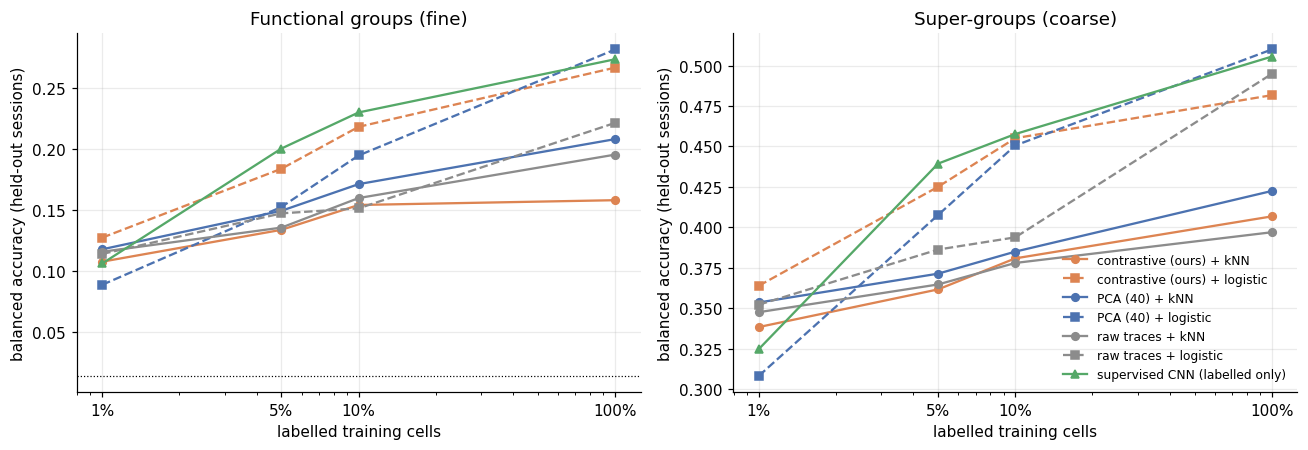

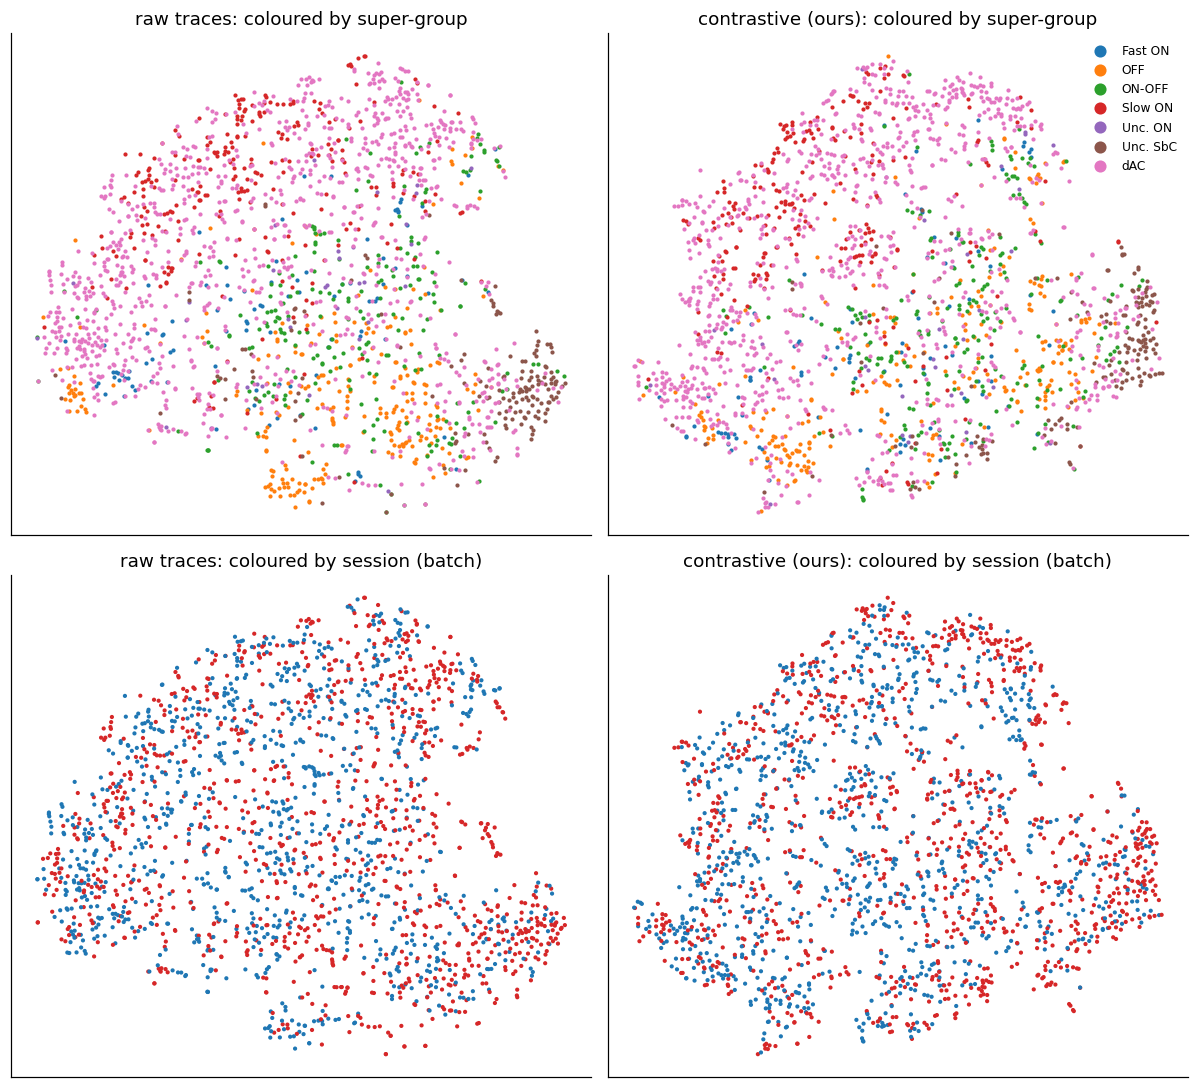

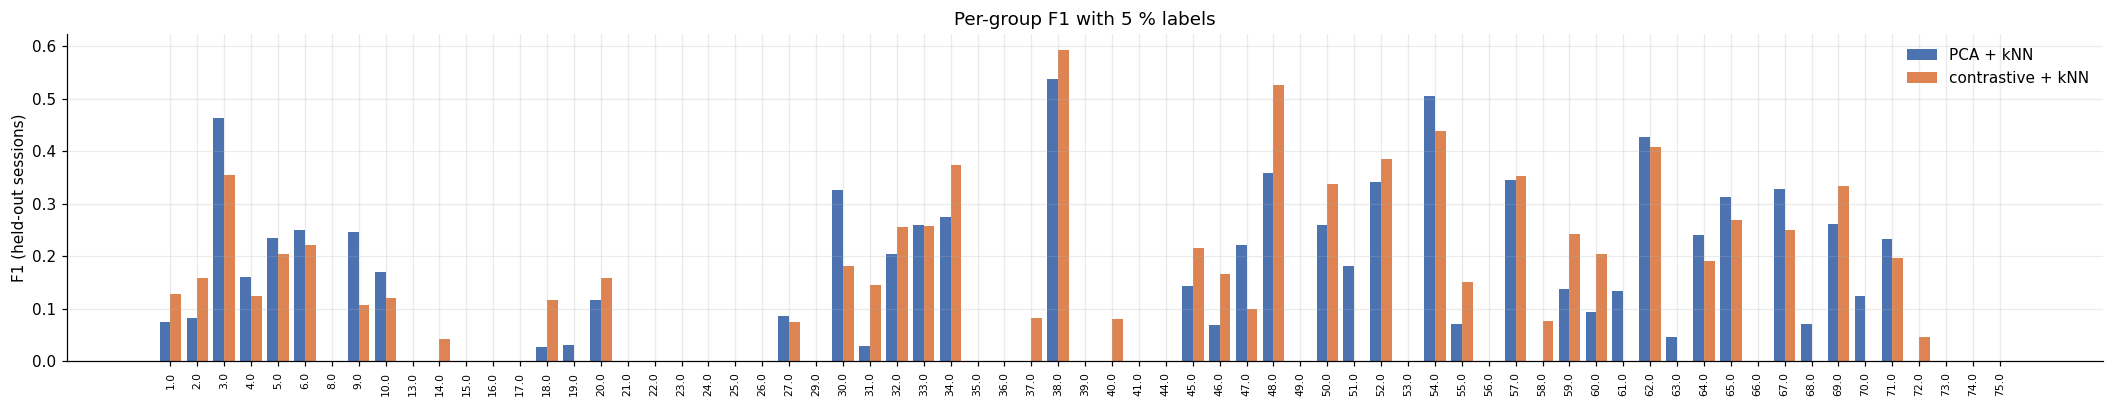

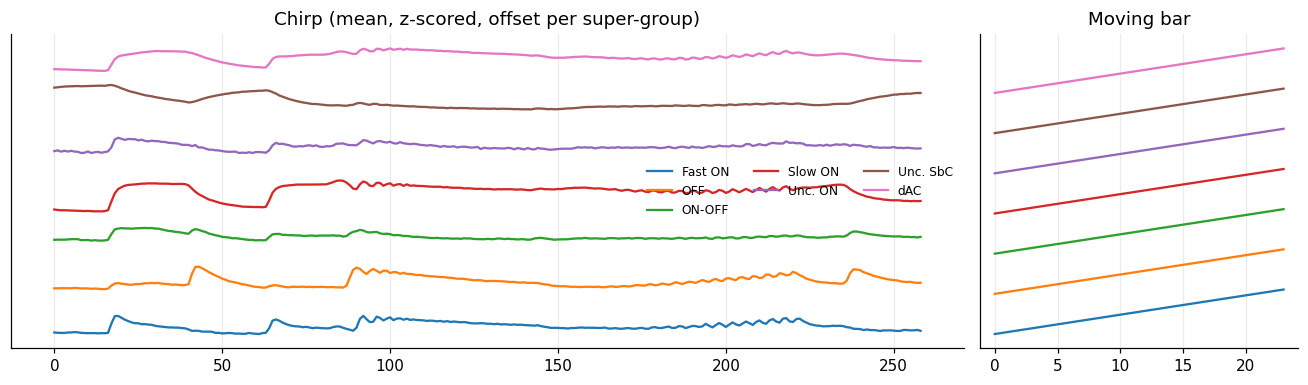

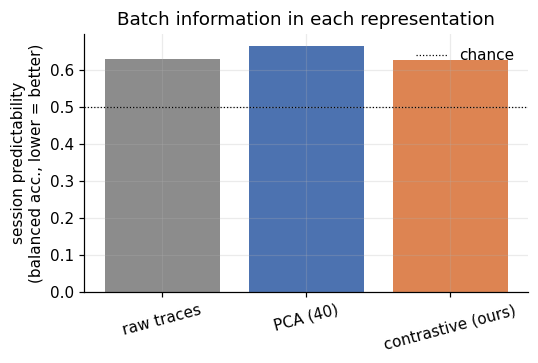

In [15]:
# --- Figures ---
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "font.size": 10})
STYLE = {"contrastive (ours) + kNN": ("#DD8452", "-o"), "contrastive (ours) + logistic": ("#DD8452", "--s"),
         "PCA (40) + kNN": ("#4C72B0", "-o"), "PCA (40) + logistic": ("#4C72B0", "--s"),
         "raw traces + kNN": ("#8C8C8C", "-o"), "raw traces + logistic": ("#8C8C8C", "--s"),
         "supervised CNN (labelled only)": ("#55A868", "-^")}

# 1) label-efficiency curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, metric, title in zip(axes, ["bal_acc", "super_bal_acc"], ["Functional groups (fine)", "Super-groups (coarse)"]):
    for meth, (col, ls) in STYLE.items():
        d = SUMMARY[SUMMARY.method == meth].sort_values("frac")
        if len(d):
            ax.plot(d.frac * 100, d[metric], ls, color=col, label=meth, ms=5)
    ax.set_xscale("log"); ax.set_xticks([1, 5, 10, 100]); ax.set_xticklabels(["1%", "5%", "10%", "100%"])
    ax.set_xlabel("labelled training cells"); ax.set_ylabel("balanced accuracy (held-out sessions)"); ax.set_title(title)
axes[0].axhline(1 / len(GROUPS), color="k", lw=0.8, ls=":")
axes[1].legend(frameon=False, fontsize=8, loc="lower right")
fig.tight_layout(); fig.savefig(OUT / "fig1_label_efficiency.png", bbox_inches="tight"); plt.show()

# 2) t-SNE of held-out cells: raw vs contrastive, coloured by super-group and by session
n = min(CFG["tsne_n"], len(TE))
sub = np.random.default_rng(0).choice(TE, n, replace=False)
emb = {}
for rep in ["raw traces", "contrastive (ours)"]:
    X = REPS[rep][sub]
    X = PCA(min(30, X.shape[1]), random_state=0).fit_transform(X) if X.shape[1] > 30 else X
    emb[rep] = TSNE(2, init="pca", perplexity=30, random_state=0).fit_transform(X)
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
cm_s = plt.get_cmap("tab10"); cm_r = plt.get_cmap("tab20")
for c, rep in enumerate(emb):
    E = emb[rep]
    for k, sname in enumerate(SUPERS):
        m = y_super[sub] == k
        axes[0, c].scatter(E[m, 0], E[m, 1], s=3, color=cm_s(k % 10), label=sname)
    axes[0, c].set_title(f"{rep}: coloured by super-group")
    sc = sess_id[sub]
    axes[1, c].scatter(E[:, 0], E[:, 1], s=3, c=[cm_r(v % 20) for v in sc])
    axes[1, c].set_title(f"{rep}: coloured by session (batch)")
axes[0, 1].legend(markerscale=4, frameon=False, fontsize=8)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([]); a.grid(False)
fig.tight_layout(); fig.savefig(OUT / "fig2_tsne.png", bbox_inches="tight"); plt.show()

# 3) per-group F1 at 5 % labels: contrastive vs PCA (kNN)
lab = sample_labeled(y_group, TR, 0.05, 0)
f1_c = f1_score(y_group[TE], fit_predict(Z, lab, "kNN"), average=None, labels=range(len(GROUPS)))
f1_p = f1_score(y_group[TE], fit_predict(PCAF, lab, "kNN"), average=None, labels=range(len(GROUPS)))
PER_GROUP = pd.DataFrame(dict(group=GROUPS, super=[G2S[g] for g in GROUPS], f1_contrastive=f1_c, f1_pca=f1_p,
                              n_test=[int((y_group[TE] == i).sum()) for i in range(len(GROUPS))]))
PER_GROUP.to_csv(OUT / "per_group_f1_5pct.csv", index=False)
fig, ax = plt.subplots(figsize=(max(8, 0.28 * len(GROUPS)), 3.8))
xs = np.arange(len(GROUPS))
ax.bar(xs - 0.2, f1_p, 0.4, color="#4C72B0", label="PCA + kNN")
ax.bar(xs + 0.2, f1_c, 0.4, color="#DD8452", label="contrastive + kNN")
ax.set_xticks(xs); ax.set_xticklabels(GROUPS, rotation=90, fontsize=7)
ax.set_ylabel("F1 (held-out sessions)"); ax.set_title("Per-group F1 with 5 % labels"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(OUT / "fig3_per_group_f1.png", bbox_inches="tight"); plt.show()

# 4) mean responses per super-group (sanity check of the data)
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6), gridspec_kw=dict(width_ratios=[3, 1]))
for k, sname in enumerate(SUPERS):
    m = y_super == k
    axes[0].plot(CHIRP[m].mean(0) + 3 * k, color=cm_s(k % 10), label=sname)
    axes[1].plot(BAR[m].mean(0) + 3 * k, color=cm_s(k % 10))
axes[0].set_title("Chirp (mean, z-scored, offset per super-group)"); axes[1].set_title("Moving bar")
axes[0].legend(frameon=False, fontsize=8, ncol=3)
for a in axes:
    a.set_yticks([])
fig.tight_layout(); fig.savefig(OUT / "fig4_mean_responses.png", bbox_inches="tight"); plt.show()

# 5) batch effect bar
if len(BATCH):
    fig, ax = plt.subplots(figsize=(5, 3.4))
    ax.bar(BATCH.representation, BATCH.session_bal_acc, color=["#8C8C8C", "#4C72B0", "#DD8452"][:len(BATCH)])
    ax.axhline(BATCH.chance.iloc[0], color="k", ls=":", lw=0.8, label="chance")
    ax.set_ylabel("session predictability\n(balanced acc., lower = better)"); ax.set_title("Batch information in each representation")
    ax.legend(frameon=False); plt.xticks(rotation=15)
    fig.tight_layout(); fig.savefig(OUT / "fig5_batch_effect.png", bbox_inches="tight"); plt.show()

In [16]:
# --- Auto-generated summary ---
def md_table(d):
    d = d.copy()
    out = ["| " + " | ".join(map(str, d.columns)) + " |", "|" + "---|" * len(d.columns)]
    for _, r in d.iterrows():
        out.append("| " + " | ".join(f"{v:.3f}" if isinstance(v, float) else str(v) for v in r.values) + " |")
    return "\n".join(out)

piv = SUMMARY.pivot(index="method", columns="frac", values="bal_acc").reset_index()
piv.columns = ["method"] + [f"{c:.0%} labels" for c in piv.columns[1:]]
lines = [f"# All-GCL few-label results{' (DEMO data)' if DEMO_MODE else ''}", "",
         f"Cells after QC: {len(df)} · functional groups: {len(GROUPS)} · sessions: {len(uniq)} ({len(test_sess)} held out for testing)", "",
         f"Columns used: {json.dumps(COLS)}", "",
         "## Balanced accuracy on held-out sessions (functional groups, mean of seeds)", md_table(piv), "",
         f"Chance level: {1 / len(GROUPS):.3f}", ""]
if len(BATCH):
    lines += ["## Session predictability (lower = less batch information)", md_table(BATCH), ""]
best = SUMMARY[SUMMARY.frac == 0.05].sort_values("bal_acc", ascending=False).head(3)
lines += ["## Automatic notes (verify before writing anything)",
          "- Best methods at 5 % labels: " + "; ".join(f"{r.method} ({r.bal_acc:.3f})" for r in best.itertuples())]
(OUT / "summary.md").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))
print("\nSaved tables and figures to:", OUT)

# All-GCL few-label results

Cells after QC: 30888 · functional groups: 69 · sessions: 8 (2 held out for testing)

Columns used: {"chirp": "chirp_snippets", "bar": "bar_snippets_t0", "supergroup": "supergroup", "group": "cluster_id", "gcl_class": null, "qi_chirp": "chirp_qidx", "qi_bar": "bar_qidx", "confidence": "prob_cluster", "session": "experimenter"}

## Balanced accuracy on held-out sessions (functional groups, mean of seeds)
| method | 1% labels | 5% labels | 10% labels | 100% labels |
|---|---|---|---|---|
| PCA (40) + kNN | 0.118 | 0.149 | 0.171 | 0.208 |
| PCA (40) + logistic | 0.089 | 0.153 | 0.195 | 0.281 |
| contrastive (ours) + kNN | 0.108 | 0.134 | 0.154 | 0.158 |
| contrastive (ours) + logistic | 0.127 | 0.184 | 0.218 | 0.266 |
| raw traces + kNN | 0.116 | 0.136 | 0.160 | 0.195 |
| raw traces + logistic | 0.114 | 0.147 | 0.151 | 0.221 |
| supervised CNN (labelled only) | 0.106 | 0.200 | 0.230 | 0.273 |

Chance level: 0.014

## Session predictability (lower = less batch 

## How to read the results

- **Fig 1.** The key comparison is at 1–5 % labels. If the contrastive embedding + kNN is clearly above PCA and raw traces there, unlabelled data has been put to use. The supervised CNN trained only on the few labelled cells shows how label-hungry an end-to-end model is.
- **Fig 2.** Good representations group cells by type (top) and mix sessions (bottom). Clusters that follow session colours indicate batch effects.
- **Fig 3.** Groups with low F1 are usually rare or functionally similar types.
- **Fig 5.** If session predictability drops from raw traces to the contrastive embedding, the representation is more robust to batch effects.

## Limitations (state them honestly)

- The All-GCL group labels are classifier outputs (trained on Baden et al. 2016), so "accuracy" here means agreement with that classifier, not with manual ground truth. High-confidence cells reduce, but do not remove, this issue.
- The summary table has trial-averaged responses. TRACE builds positive pairs from different subsets of single trials; that needs the NWB files (next step).
- Augmentations were chosen by hand; time shifts that are too large can change the cell type's meaning (response latency is informative).

## Next steps

1. Use single trials from the NWB files and build positive pairs from trial subsets, as in TRACE.
2. Add session-adversarial or batch-aware contrastive objectives and test whether few-label accuracy on new sessions improves.
3. Compare against the 75 original Baden clusters and look at which types the embedding confuses.